In [1]:
!pip install --upgrade google-cloud-bigquery
from google.colab import auth
from google.cloud import bigquery
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import pearsonr, wilcoxon, normaltest, shapiro, mannwhitneyu, kruskal
import statsmodels.api as sm
auth.authenticate_user()
client = bigquery.Client(project="data-analytics-mate")
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#create params for next vizualisations
my_colors = [
    "#2A9D8F",  # Turquoise
    "#E9C46A",  # Yellow
    "#E76F51",   # Coral
    "#8ECAE6"  # light teal
]

#Set the global style
sns.set_theme(
    style="whitegrid", #grid on white
    context="notebook", #normal size of elements
    palette=my_colors
)


In [3]:
#making query for download information
query = """
SELECT
s.date,
s.ga_session_id as session_id,
sp.continent,
sp.country,
sp.device,
sp.browser,
sp.mobile_model_name as device_model,
sp.operating_system,
sp.language,
sp.name as traffic_source,
sp.channel as traffic_channel,
acs.account_id AS account_id,
CASE WHEN a.is_verified = 1 THEN 1 ELSE 0 END AS is_verified,
CASE WHEN a.is_unsubscribed = 0 THEN 1 ELSE 0 END AS is_subscribed,
IFNULL (p.category, 'no order') as product_category,
IFNULL (p.name, 'no order') as product_name,
IFNULL (p.price, NULL) as product_price,
IFNULL (p.short_description, 'no order') as product_description

 FROM `data-analytics-mate.DA.session` as s
 LEFT JOIN `data-analytics-mate.DA.session_params` as sp
 ON s.ga_session_id = sp.ga_session_id
 LEFT JOIN `data-analytics-mate.DA.account_session` as acs
 ON s.ga_session_id = acs.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` as a
ON acs.account_id = a.id
LEFT JOIN `data-analytics-mate.DA.order` as o
ON s.ga_session_id = o.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` as p
ON o.item_id = p.item_id
"""

In [4]:
query_job = client.query(query)
results = query_job.result()

#Work with datas: preparation, cleaning, standardization
##Робота з даними: підготовка, очищення, стандартизація

In [5]:
df = results.to_dataframe()
df.head()

,date,session_id,continent,country,device,browser,device_model,operating_system,language,traffic_source,traffic_channel,account_id,is_verified,is_subscribed,product_category,product_name,product_price,product_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,<Other>,Paid Search,<NA>,0,0,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,(organic),Organic Search,<NA>,0,0,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,<Other>,Web,zh,(direct),Direct,<NA>,0,0,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,(direct),Direct,<NA>,0,0,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,(direct),Direct,<NA>,0,0,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 349545 non-null  dbdate 
 1   session_id           349545 non-null  Int64  
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   device_model         349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   language             235279 non-null  object 
 9   traffic_source       349545 non-null  object 
 10  traffic_channel      349545 non-null  object 
 11  account_id           27945 non-null   Int64  
 12  is_verified          349545 non-null  Int64  
 13  is_subscribed        349545 non-null  Int64  
 14  product_category     349545 non-null  object 
 15  product_name     

In [7]:
df['date'] = pd.to_datetime(df['date'])
df['session_id'] = df['session_id'].astype('string')
df['account_id'] = df['account_id'].astype('string')
df['is_verified'] = df['is_verified'].astype(bool)
df['is_subscribed'] = df['is_subscribed'].astype(bool)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 349545 non-null  datetime64[ns]
 1   session_id           349545 non-null  string        
 2   continent            349545 non-null  object        
 3   country              349545 non-null  object        
 4   device               349545 non-null  object        
 5   browser              349545 non-null  object        
 6   device_model         349545 non-null  object        
 7   operating_system     349545 non-null  object        
 8   language             235279 non-null  object        
 9   traffic_source       349545 non-null  object        
 10  traffic_channel      349545 non-null  object        
 11  account_id           27945 non-null   string        
 12  is_verified          349545 non-null  bool          
 13  is_subscribed 

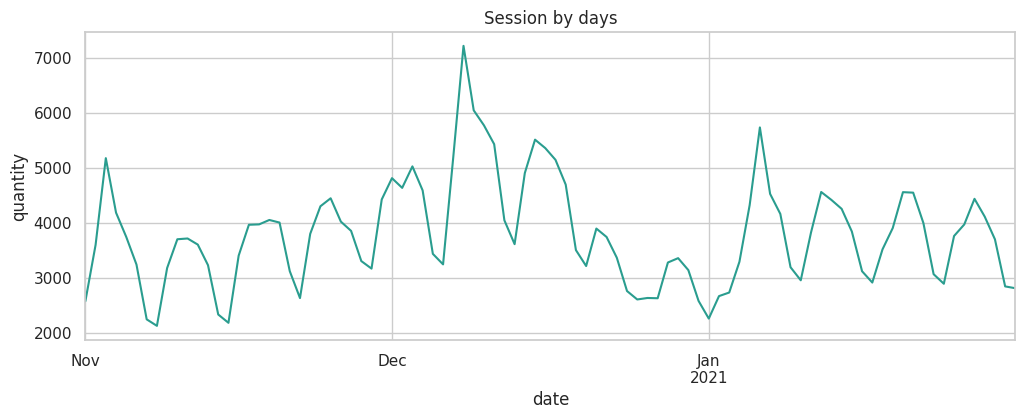

In [8]:
#checking the session dates column for outliers and its range.

daily_session = df.groupby('date').size()
plt.figure(figsize=(12, 4))
daily_session.plot(kind='line', color=my_colors, linewidth=1.5)
plt.title('Session by days')
plt.xlabel('date')
plt.ylabel('quantity')
plt.show()

In [9]:
df['account_id'].value_counts()

,count
account_id,
649280,1
676055,1
677981,1
672927,1
653089,1
...,...
652887,1
675528,1
660454,1


In [10]:
df['account_id'] = df['account_id'].fillna('guest')
display(df['account_id'].value_counts())
print(f'Percent of sessions with no registration account: {(df['account_id'] == 'guest').mean() * 100:.1f}%')

,count
account_id,
guest,321600
649280,1
676055,1
677981,1
672927,1
...,...
652887,1
675528,1
660454,1


Percent of sessions with no registration account: 92.0%


In [11]:
print(df.duplicated().sum())

0


In [12]:
print(df['date'].min())
print(df['date'].max())

2020-11-01 00:00:00
2021-01-31 00:00:00


In [13]:
df['continent'].value_counts()

,count
continent,
Americas,193179
Asia,83113
Europe,65135
Oceania,3703
Africa,3620
(not set),795


In [14]:
df['country'].unique()

array(['United States', 'United Kingdom', 'Norway', 'Nigeria', 'China',
       'Germany', '(not set)', 'Ecuador', 'Japan', 'Canada', 'Italy',
       'Indonesia', 'South Korea', 'Belgium', 'Pakistan',
       'United Arab Emirates', 'Uruguay', 'Israel', 'Czechia', 'India',
       'Taiwan', 'Georgia', 'Portugal', 'Thailand', 'Bangladesh',
       'Turkey', 'Vietnam', 'Philippines', 'France', 'Switzerland',
       'Greece', 'Sweden', 'Malaysia', 'Slovenia', 'Argentina',
       'Singapore', 'Spain', 'Brazil', 'Denmark', 'Dominican Republic',
       'Australia', 'Mexico', 'Colombia', 'Netherlands', 'Poland',
       'Lithuania', 'Ukraine', 'Chile', 'Oman', 'Ireland', 'Kuwait',
       'New Zealand', 'Peru', 'Sri Lanka', 'Tunisia', 'Lebanon',
       'Puerto Rico', 'Saudi Arabia', 'Egypt', 'Slovakia',
       'Bosnia & Herzegovina', 'El Salvador', 'Bahrain', 'Jordan',
       'Bolivia', 'Austria', 'Albania', 'Hong Kong', 'Paraguay', 'Iraq',
       'Panama', 'Guatemala', 'Kazakhstan', 'Nepal', 'Cost

In [15]:
df['continent'] = df['continent'].replace('(not set)', 'unknown')
df['country'] = df['country'].replace('(not set)', 'unknown')
percent_unknown_country = (df['country'] == 'unknown').sum() / df.shape[0] *100
percent_unknown_continent = (df['continent'] == 'unknown').sum() / df.shape[0] *100
print(f"Percent of unknown country: {percent_unknown_country:.2f}%")
print(f"Percent of unknown continent: {percent_unknown_continent:.2f}%")
print(f"Count of unique countries: {df['country'].nunique()}")

Percent of unknown country: 0.80%
Percent of unknown continent: 0.23%
Count of unique countries: 108


In [16]:
df['country'].value_counts()

,count
country,
United States,153470
India,32763
Canada,25994
United Kingdom,11003
France,6958
...,...
Paraguay,70
Malta,69
Trinidad & Tobago,68


In [17]:
df['continent'].value_counts()

,count
continent,
Americas,193179
Asia,83113
Europe,65135
Oceania,3703
Africa,3620
unknown,795


In [18]:
df['device'].value_counts()

,count
device,
desktop,204429
mobile,137267
tablet,7849


In [19]:
df['browser'].value_counts()

,count
browser,
Chrome,238460
Safari,83254
<Other>,8930
Edge,8023
Firefox,6433
Android Webview,4445


In [20]:
df['browser'] = df['browser'].replace('<Other>', 'Other browser')
df['browser'].value_counts()

,count
browser,
Chrome,238460
Safari,83254
Other browser,8930
Edge,8023
Firefox,6433
Android Webview,4445


In [21]:
df['device_model'].value_counts()

,count
device_model,
Chrome,97254
iPhone,71326
Safari,70891
<Other>,70839
ChromeBook,19084
Edge,7907
iPad,5090
Firefox,4874
Pixel 4 XL,1246


In [22]:
df['operating_system'].value_counts()

,count
operating_system,
Web,203909
Windows,40937
iOS,40102
Android,29808
Macintosh,26116
<Other>,8673


In [23]:
df['operating_system'] = df['operating_system'].replace('<Other>', 'Other OS')
df['operating_system'].value_counts()

,count
operating_system,
Web,203909
Windows,40937
iOS,40102
Android,29808
Macintosh,26116
Other OS,8673


In [24]:
df['language'].value_counts()

,count
language,
en-us,159893
en-gb,24774
zh,12222
en,11518
en-ca,9332
es-es,5760
fr,5652
de,3387
ko,2741


In [25]:
df['language'] = df['language'].replace({'en-us': 'English', 'en-gb': 'English', 'en': 'English',
                                                 'en-ca': 'English', 'es-es': 'Spanish', 'zh': 'Chinese', 'fr': 'French', 'de': 'German', 'ko': 'Korean'})
df['language'] = df['language'].fillna('unknown')
display(df['language'].value_counts())
print(f'Percent of session without identified language: {(df['language'] == 'unknown').mean() * 100:.1f}%')


,count
language,
English,205517
unknown,114266
Chinese,12222
Spanish,5760
French,5652
German,3387
Korean,2741


Percent of session without identified language: 32.7%


In [26]:
df['traffic_source'].value_counts()

,count
traffic_source,
(organic),119024
(direct),81382
<Other>,66289
(referral),61436
(data deleted),21414


In [27]:
df['traffic_source'] = df['traffic_source'].replace({'<Other>': 'unknown', '(data deleted)': 'unknown'})
df['traffic_source'] = df['traffic_source'].str.strip('()')
df['traffic_source'].value_counts()

,count
traffic_source,
organic,119024
unknown,87703
direct,81382
referral,61436


In [28]:
df['traffic_channel'].value_counts()

,count
traffic_channel,
Organic Search,124425
Paid Search,94341
Direct,81382
Social Search,27914
Undefined,21483


In [29]:
df['product_category'].value_counts()

,count
product_category,
no order,316007
Bookcases & shelving units,7630
Chairs,5952
Sofas & armchairs,4301
Tables & desks,2941
Beds,2926
Cabinets & cupboards,2318
Outdoor furniture,2229
Children's furniture,1702


In [30]:
df['product_name'].value_counts()

,count
product_name,
no order,316007
BESTÅ,1257
GRÖNLID,915
TROFAST,813
IVAR,754
...,...
BÅTSFJORD,5
BYLLAN,4
NILSOVE / NORNA,4


In [31]:
df['product_description'].value_counts()

,count
product_description,
no order,316007
Chair,659
Armchair,382
3-seat sofa,333
3-seat sofa-bed,286
...,...
"Drawer unit on castors, 45x55 cm",3
Cover for footstool module,3
Headset/tablet stand,3


In [32]:
display(df['product_price'].describe())
print(f'Percent of session without sales: {(df['product_price'].isna()).mean() * 100:.1f}%')

,product_price
count,33538.000000
mean,953.298679
std,1317.001775
min,3.000000
25%,170.000000
50%,445.000000
75%,1195.000000
max,9585.000000


Percent of session without sales: 90.4%


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 349545 non-null  datetime64[ns]
 1   session_id           349545 non-null  string        
 2   continent            349545 non-null  object        
 3   country              349545 non-null  object        
 4   device               349545 non-null  object        
 5   browser              349545 non-null  object        
 6   device_model         349545 non-null  object        
 7   operating_system     349545 non-null  object        
 8   language             349545 non-null  object        
 9   traffic_source       349545 non-null  object        
 10  traffic_channel      349545 non-null  object        
 11  account_id           349545 non-null  string        
 12  is_verified          349545 non-null  bool          
 13  is_subscribed 

##Conclusions / Висновки


З бази даних BigQuery вивантажено детальну інформацію, зібрану інтернет-магазином про всі сесії користувачів за період з 01.11.2020 по 31.01.2021 (date). Дані об'єднано з шести таблиць (session, session_params, account_session, account, order, product) через LEFT JOIN від таблиці сесій. Один рядок відповідає одній сесії, у якій може бути не більше одного придбаного товару, а кожен зареєстрований акаунт зустрічається лише в одній сесії.

Усього зафіксовано 349 545 сесій (session_id) з 5 континентів (continent), для 0,23% сесій континент не визначено. Сесії здійснювались із 107 країн (country), для 0,8% сесій країну не визначено. Користувачі заходили з трьох типів пристроїв (device), 5 браузерів (browser) та 5  операційних систем (operating_system), рідкісні значення об'єднано в категорії «Other browser» та «Other OS». Серед мов браузера (language) виділено шість основних (English, Spanish, Chinese, French, German, Korean); для 32.7% сесій мову не визначено.

Колонки traffic_source та traffic_channel описують, звідки користувач перейшов на сайт. Джерела: organic, direct, referral, unknown. Канали: Organic Search, Paid Search, Direct, Social Search, Undefined (6,1% сесій).

У колонці account_id зазначено номер акаунта, якщо користувач зареєстрований, або guest, якщо ні (гості становлять 92% сесій). Колонки is_verified і is_subscribed показують, чи верифіковано акаунт та чи підписаний користувач на розсилку; для гостей їм присвоєно False. Останні чотири колонки (product_category, product_name, product_price, product_description) містять інформацію про придбаний товар; у сесіях без покупки (90.4% сесій) вони не заповнені.

Підсумок структури датасету:

- кількість колонок: 18;
- числові: 1 (product_price, float);
- дата й час: 1 (date);
- булеві: 2 (is_verified, is_subscribed);
- ідентифікатори (string): 2 (session_id, account_id);
- текстові (категоріальні): 12 (continent, country, device, browser, device_model, operating_system, language, traffic_source, traffic_channel, product_category, product_name, product_description);
- кількість сесій: 349 545; повних дублікатів немає;
- період: з 01.11.2020 по 31.01.2021.


Detailed information collected by the online store regarding all user sessions from November 1, 2020, to January 31, 2021, was extracted from the BigQuery database. The data was aggregated from six tables (`session`, `session_params`, `account_session`, `account`, `order`, and `product`) using `LEFT JOIN` operations, with the `session` table serving as the base. Each row represents a single session, which may contain at most one purchased item; furthermore, each registered account appears in only one session.

A total of 349,545 sessions (`session_id`) were recorded across 5 continents (`continent`), with the continent remaining unidentified for 0.23% of these sessions. The sessions originated from 107 countries (`country`), with the country unidentified for 0.8% of the sessions. Users accessed the site via three device types (`device`), 5 browsers (`browser`), and 5 operating systems (`operating_system`); infrequent values ​​were grouped into the categories "Other browser" and "Other OS." Regarding browser language (`language`), six primary languages ​​were identified (English, Spanish, Chinese, French, German, and Korean), while the language remained unidentified for 32.7% of the sessions.

The `traffic_source` and `traffic_channel` columns describe how users arrived at the site. Sources include: organic, direct, referral, and unknown. Channels include: Organic Search, Paid Search, Direct, Social Search, and Undefined (accounting for 6.1% of sessions).

The `account_id` column indicates the account number for registered users, or "guest" for unregistered users (guests account for 92% of the sessions). The `is_verified` and `is_subscribed` columns indicate whether an account is verified and whether the user is subscribed to the newsletter; for guest users, these are set to `False`. The last four columns (`product_category`, `product_name`, `product_price`, `product_description`) contain information about the purchased item; for sessions without a purchase (90.4% of sessions), these fields are empty.

Dataset structure summary:

- Number of columns: 18;
- Numeric: 1 (`product_price`, float);
- Date and time: 1 (`date`);
- Boolean: 2 (`is_verified`, `is_subscribed`);
- Identifiers (string): 2 (`session_id`, `account_id`);
- Textual (categorical): 12 (`continent`, `country`, `device`, `browser`, `device_model`, `operating_system`, `language`, `traffic_source`, `traffic_channel`, `product_category`, `product_name`, `product_description`);
- Number of sessions: 349,545; no exact duplicates;
- Period: from November 1, 2020, to January 31, 2021.

# Main Metrics / Основні метрики




In [34]:
print(f"Count of countries: {df['country'].nunique()}")
print(f"Count of registered users: {df['account_id'].nunique() - 1}")
print(f"Count of orders: {df['product_price'].count()}")
print(f"Total revenue: {df['product_price'].sum() / 1_000_000 :.2f}$M")
print(f"Conversion rate (CR): {df['product_price'].count() / df['session_id'].count() * 100:.2f}%")
print(f"Average order value (AOV): {df['product_price'].sum() / df['product_price'].count():.2f}$")
print(f"Median order value: {df['product_price'].median():.2f}$")
print(f"Revenue per session (RPS): {df['product_price'].sum() / df['session_id'].count():.2f}$")

Count of countries: 108
Count of registered users: 27945
Count of orders: 33538
Total revenue: 31.97$M
Conversion rate (CR): 9.59%
Average order value (AOV): 953.30$
Median order value: 445.00$
Revenue per session (RPS): 91.47$


In [35]:
continent_stats = (df.groupby('continent').
        agg(sessions=('session_id', 'count'),
        orders=('product_price', 'count'),
        revenue=('product_price', 'sum'))
    .sort_values('revenue', ascending=False))
continent_stats['revenue_share_%'] = continent_stats['revenue'] / continent_stats['revenue'].sum() * 100
continent_stats['CR_%'] = continent_stats['orders'] / continent_stats['sessions'] * 100
continent_stats['AOV'] = continent_stats['revenue'] / continent_stats['orders']

continent_stats.round(2)

,sessions,orders,revenue,revenue_share_%,CR_%,AOV
continent,,,,,,
Americas,193179,18553,17665280.0,55.25,9.60,952.15
Asia,83113,7950,7601298.3,23.78,9.57,956.14
Europe,65135,6261,5934624.2,18.56,9.61,947.87
Oceania,3703,364,365230.2,1.14,9.83,1003.38
Africa,3620,339,331231.0,1.04,9.36,977.08
unknown,795,71,74067.4,0.23,8.93,1043.20


In [36]:
country_stats = (df.groupby('country').
        agg(sessions=('session_id', 'count'),
        orders=('product_price', 'count'),
        revenue=('product_price', 'sum'))
    .sort_values('revenue', ascending=False))
country_stats['revenue_share_%'] = country_stats['revenue'] / country_stats['revenue'].sum() * 100
country_stats['CR_%'] = country_stats['orders'] / country_stats['sessions'] * 100
country_stats['AOV'] = country_stats['revenue'] / country_stats['orders']
country_stats.round(2).head(5)

,sessions,orders,revenue,revenue_share_%,CR_%,AOV
country,,,,,,
United States,153470,14673,13943553.9,43.61,9.56,950.29
India,32763,3029,2809762.0,8.79,9.25,927.62
Canada,25994,2560,2437921.0,7.63,9.85,952.31
United Kingdom,11003,1029,938317.9,2.93,9.35,911.87
France,6958,678,710692.8,2.22,9.74,1048.22


In [37]:
category_stats = (df.groupby('product_category').
        agg(orders=('product_price', 'count'),
        revenue=('product_price', 'sum'))
    .sort_values('revenue', ascending=False))
category_stats['revenue_share_%'] = category_stats['revenue'] / category_stats['revenue'].sum() * 100
category_stats['orders_share_%'] = category_stats['orders'] / category_stats['orders'].sum() * 100
category_stats['AOV'] = category_stats['revenue'] / category_stats['orders']
category_stats.index.name = 'Product Category'
category_stats.round(2).head(10)

,orders,revenue,revenue_share_%,orders_share_%,AOV
Product Category,,,,,
Sofas & armchairs,4301,8388254.5,26.24,12.82,1950.30
Chairs,5952,6147748.8,19.23,17.75,1032.89
Beds,2926,4919725.0,15.39,8.72,1681.38
Bookcases & shelving units,7630,3640818.1,11.39,22.75,477.17
Cabinets & cupboards,2318,2336499.5,7.31,6.91,1007.98
Outdoor furniture,2229,2142222.2,6.70,6.65,961.07
Tables & desks,2941,1790307.5,5.60,8.77,608.74
Chests of drawers & drawer units,1452,906562.5,2.84,4.33,624.35
Bar furniture,1092,735503.0,2.30,3.26,673.54


In [38]:
top_country = df.groupby('country')['product_price'].sum().idxmax()
print(f'Revenue by category by {top_country}')
df[df['country'] == top_country].groupby('product_category')['product_price'].sum().sort_values(ascending=False).head(10)

Revenue by category by United States


,product_price
product_category,
Sofas & armchairs,3707144.5
Chairs,2619773.8
Beds,2213058.0
Bookcases & shelving units,1567606.9
Cabinets & cupboards,994545.5
Outdoor furniture,929245.2
Tables & desks,777865.0
Chests of drawers & drawer units,382388.0
Bar furniture,330805.0


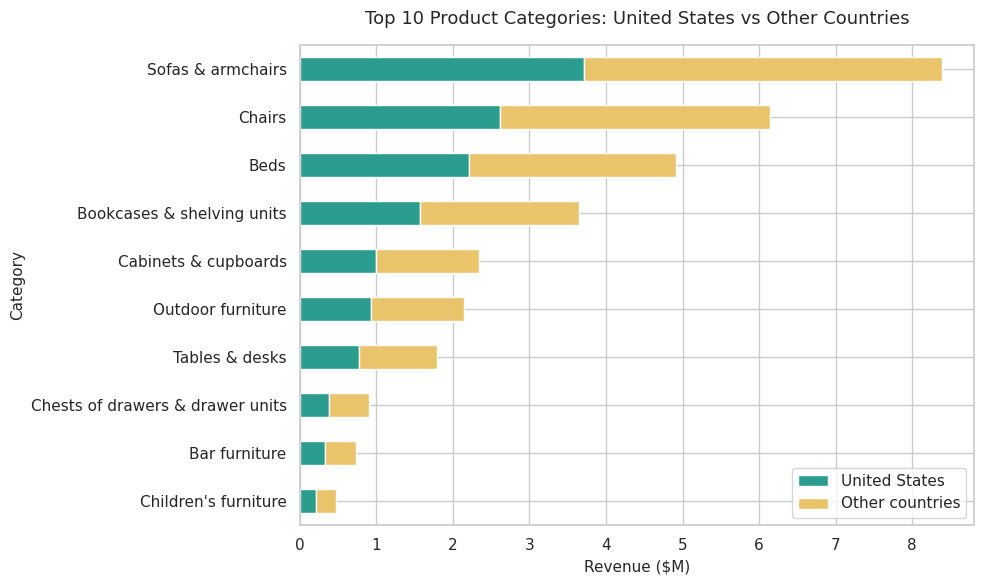

In [39]:
top_categories_global = df.groupby('product_category')['product_price'].sum().nlargest(10) / 1_000_000

top_categories_country = df[df['country'] == top_country].groupby('product_category')['product_price'].sum().reindex(top_categories_global.index, fill_value=0) / 1_000_000

top_categories_other = top_categories_global - top_categories_country

plot_data = pd.DataFrame({top_country: top_categories_country,f'Other countries': top_categories_other})

fig, ax = plt.subplots(figsize=(10, 6))

sorted_data = plot_data.sort_values(by=plot_data.columns[1], ascending=True)

sorted_data.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=my_colors
)

ax.set_title(f'Top 10 Product Categories: {top_country} vs Other Countries', fontsize=13, pad=15)
ax.set_xlabel('Revenue ($M)', fontsize=11)
ax.set_ylabel('Category', fontsize=11)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

,sessions,orders,revenue,revenue_share_%,CR_%,AOV
device,,,,,,
desktop,204429,19702,18864039.0,59.00,9.64,957.47
mobile,137267,13113,12384225.8,38.73,9.55,944.42
tablet,7849,723,723466.3,2.26,9.21,1000.64


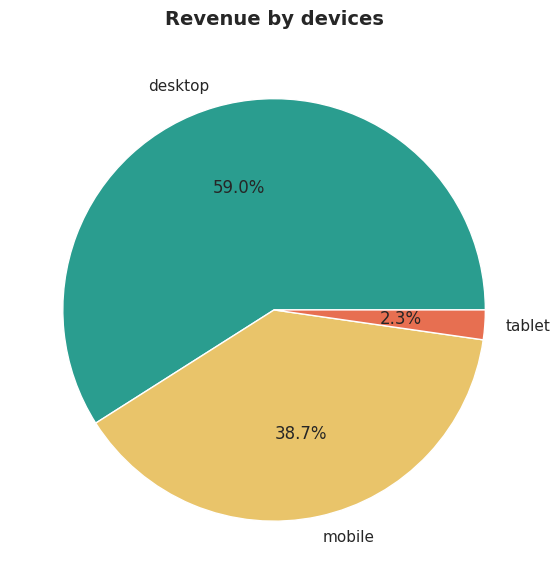

In [40]:
device_stats = (df.groupby('device').
        agg(sessions=('session_id', 'count'),
            orders=('product_price', 'count'),
        revenue=('product_price', 'sum'))
    .sort_values('revenue', ascending=False))
device_stats['revenue_share_%'] = device_stats['revenue'] / device_stats['revenue'].sum() * 100
device_stats['CR_%'] = device_stats['orders'] / device_stats['sessions'] * 100
device_stats['AOV'] = device_stats['revenue'] / device_stats['orders']
display(device_stats.round(2))

plt.figure(figsize=(8, 6))

plt.pie(device_stats['revenue'], labels=device_stats.index, autopct='%1.1f%%', colors=my_colors)

plt.title('Revenue by devices', fontsize=14, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()

,sessions,orders,revenue,revenue_share_%,CR_%,AOV
traffic_channel,,,,,,
Organic Search,124425,11921,11433151.6,35.76,9.58,959.08
Paid Search,94341,9042,8511049.4,26.62,9.58,941.28
Direct,81382,7800,7494923.4,23.44,9.58,960.89
Social Search,27914,2716,2532105.7,7.92,9.73,932.29
Undefined,21483,2059,2000501.0,6.26,9.58,971.59


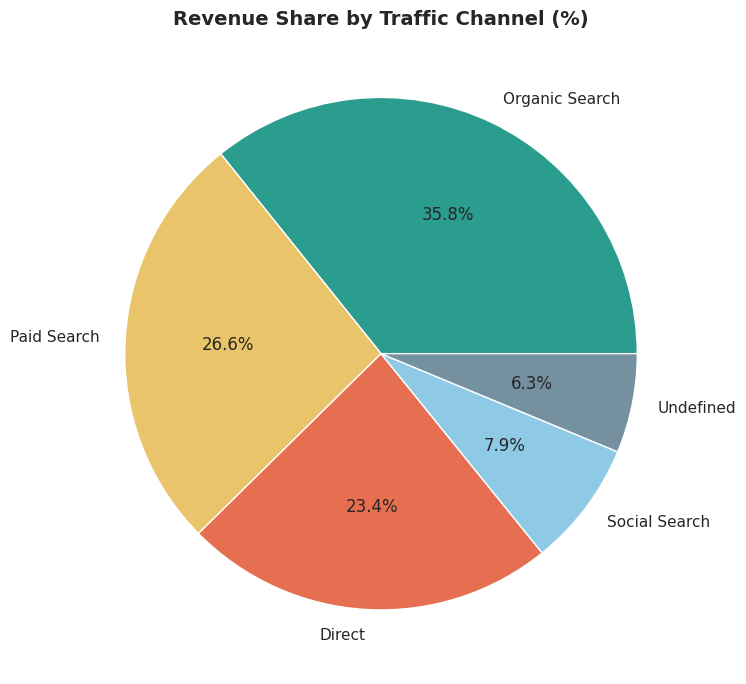

In [41]:
traffic_stats = (df.groupby('traffic_channel').
        agg(sessions=('session_id', 'count'),
            orders=('product_price', 'count'),
        revenue=('product_price', 'sum'))
    .sort_values('revenue', ascending=False))
traffic_stats['revenue_share_%'] = traffic_stats['revenue'] / traffic_stats['revenue'].sum() * 100
traffic_stats['CR_%'] = traffic_stats['orders'] / traffic_stats['sessions'] * 100
traffic_stats['AOV'] = traffic_stats['revenue'] / traffic_stats['orders']
display(traffic_stats.round(2))

plt.figure(figsize=(9, 7))

plt.pie(traffic_stats['revenue'], labels=traffic_stats.index, autopct='%1.1f%%', colors=['#2A9D8F', '#E9C46A', '#E76F51', '#8ECAE6', '#75909f'])

plt.title(
    'Revenue Share by Traffic Channel (%)',
    fontsize=14,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

In [42]:
percent_unsubscribed_accounts = (
    len(df[(df['account_id'] != 'guest') & (df['is_subscribed'] == False)])
    / len(df[df['account_id'] != 'guest'])
    * 100
)
print(f"Percent of unsubscribed accounts: {percent_unsubscribed_accounts:.2f}%")

Percent of unsubscribed accounts: 16.94%


In [43]:
language_stats = (df.groupby('language').
        agg(sessions=('session_id', 'count'),
            orders=('product_price', 'count'),
        revenue=('product_price', 'sum'))
    .sort_values('revenue', ascending=False))
language_stats['revenue_share_%'] = language_stats['revenue'] / language_stats['revenue'].sum() * 100
language_stats['CR_%'] = language_stats['orders'] / language_stats['sessions'] * 100
language_stats['AOV'] = language_stats['revenue'] / language_stats['orders']
display(language_stats.round(2))



,sessions,orders,revenue,revenue_share_%,CR_%,AOV
language,,,,,,
English,205517,19644,18671574.0,58.40,9.56,950.50
unknown,114266,11007,10597901.4,33.15,9.63,962.83
Chinese,12222,1204,1053040.6,3.29,9.85,874.62
French,5652,557,579024.5,1.81,9.85,1039.54
Spanish,5760,550,514573.1,1.61,9.55,935.59
Korean,2741,272,298528.8,0.93,9.92,1097.53
German,3387,304,257088.7,0.80,8.98,845.69


##Conclusions / Висновки




**Загалом:**: за період 01.11.2020–31.01.2021 сайт отримав 349545 сесій, 33538 замовлень і 31,97млн.дол. доходу. Конверсія становить 9,59%, середній чек 953дол., а медіанний - 445дол., дохід на сесію 91,47дол. Велика різниця між середнім і медіаною показує те, що розподіл цін скошений вправо: невелика кількість дорогих товарів суттєво піднімає середнє.

**Географія:** дохід по континентах сильно сконцентрований: Америка дає 55,3%, Азія 23,8%, Європа 18,6%, а Африка, Океанія й невизначені регіони разом лише 2,4%. Щодо країн: США приносять 43,6% доходу, а разом з Індією (8,8%) та Канадою (7,6%) частка зростає до 60%.

**Товари:** три категорії (Sofas & armchairs, Chairs, Beds) дають 60,9% доходу. Кількість замовлень і дохід показують різну картину: Bookcases & shelving units лідирують за замовленнями (22,8%), але приносять лише 11,4% доходу (середній чек $477), тоді як Sofas & armchairs мають 12,8% замовлень і 26,2% доходу (чек 1 950 дол.). Структура категорій у США майже копіює світову: частка США в кожній із топ-10 категорій становить трохи менше 50%

**Сегменти:** за пристроями desktop дає 59,0% доходу, mobile 38,7%, tablet лише 2,3%. За каналами лідирують Organic Search (35,8%), Paid Search (26,6%) і Direct (23,4%). За мовою браузера 58,4% доходу припадає на English, а 33,2% на сесії без визначеної мови. Для всіх зрізів частка доходу майже збігається з часткою сесій, конверсія тримається в межах 9,0–9,9%, а середній чек у межах $930–1 000.



**Overall:** During the period from November 1, 2020, to January 31, 2021, the website recorded 349,545 sessions, 33,538 orders, and 31.97 million dol. in revenue. The conversion rate stands at 9.59%, with an average order value of 953 dol. and a median of 445 dol.; revenue per session is 91.47 dol. The significant gap between the mean and the median indicates that the price distribution is right-skewed: a small number of high-priced items substantially inflates the average.

**Geography:** Revenue is highly concentrated by continent: the Americas account for 55.3%, Asia for 23.8%, and Europe for 18.6%, while Africa, Oceania, and undefined regions combined contribute only 2.4%. Regarding individual countries, the USA generates 43.6% of revenue; when combined with India (8.8%) and Canada (7.6%), this share rises to 60%.

**Products:** Three categories—Sofas & armchairs, Chairs, and Beds—account for 60.9% of total revenue. There is a notable difference between order volume and revenue generation: "Bookcases & shelving units" lead in terms of orders (22.8%) but contribute only 11.4% of revenue (with an average order value of 477dol.). In contrast, "Sofas & armchairs" account for 12.8% of orders but generate 26.2% of revenue (with an average order value of $1,950). The category structure in the US closely mirrors the global pattern: the US share in each of the top 10 categories is just under 50%.

**Segments:** By device, desktop accounts for 59.0% of revenue, mobile for 38.7%, and tablets for only 2.3%. In terms of channels, Organic Search (35.8%), Paid Search (26.6%), and Direct (23.4%) lead the way. By browser language, English accounts for 58.4% of revenue, while 33.2% of revenue comes from sessions where the language could not be identified. Across all segments, the share of revenue is nearly identical to the share of sessions; the conversion rate remains within the 9.0–9.9% range, and the average order value falls between 930dol. and 1,000dol.

##Dynamic sales

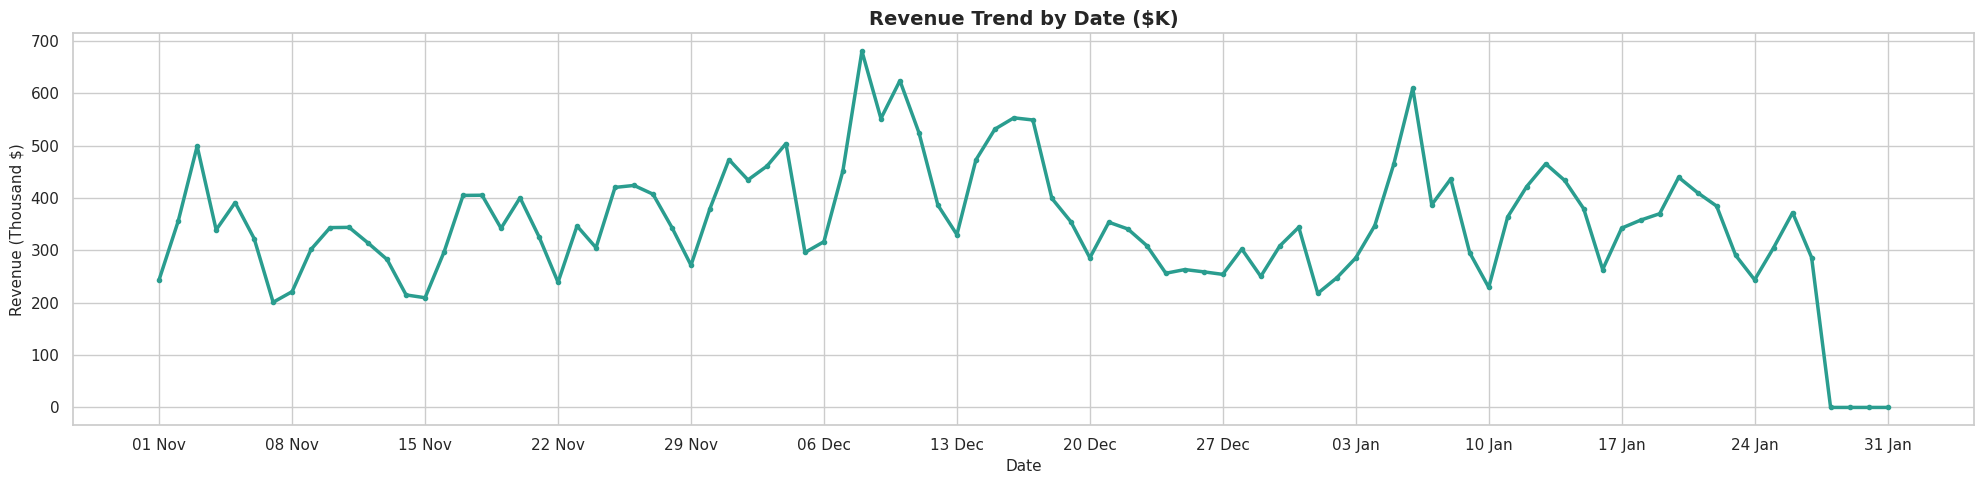

In [44]:
df_sales_date = df.groupby('date')['product_price'].sum()
df_sales_date_K = df_sales_date / 1_000

df_sales_date_K.index = pd.to_datetime(df_sales_date_K.index).strftime('%d %b')

plt.figure(figsize=(20, 5))

df_sales_date_K.plot(
    kind='line',
    color = my_colors,
    linewidth=2.5,
    marker='o',
    markersize=3,
)

plt.title('Revenue Trend by Date ($K)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=11)
plt.ylabel('Revenue (Thousand $)', fontsize=11)

tick_positions = range(0, len(df_sales_date_K), 7)
tick_labels = df_sales_date_K.index[tick_positions]

plt.xticks(tick_positions, tick_labels)

plt.tight_layout()
plt.show()

In [45]:
df['day_of_week'] = df['date'].dt.day_name()

top_category_revenue = (df.groupby('product_category')['product_price'].sum().sort_values(ascending=False)
)

top_10_categories = top_category_revenue.head(10).index

df_top10 = df[df['product_category'].isin(top_10_categories)]
pivot_sales = (
    df_top10.pivot_table(
        index='product_category',
        columns='day_of_week',
        values='product_price',
        aggfunc='sum',
    )
    / 1_000
)

days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
pivot_sales = pivot_sales[days_order]

row_gradient_table = pivot_sales.style.background_gradient(
    axis=1, cmap='crest'
).format(
    '{:.1f}'
)
row_gradient_table



day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
product_category,,,,,,,
Bar furniture,97.0,103.3,133.8,125.1,97.8,75.1,103.5
Beds,666.9,850.0,872.7,763.2,745.5,590.2,431.2
Bookcases & shelving units,482.5,631.7,676.4,553.9,483.0,396.5,416.7
Cabinets & cupboards,370.3,382.7,400.9,383.0,318.9,263.1,217.6
Chairs,869.7,1057.4,925.0,928.8,938.3,694.2,734.5
Chests of drawers & drawer units,142.4,162.0,152.9,127.8,115.6,101.9,103.9
Children's furniture,76.6,83.5,82.1,67.1,57.2,48.7,52.5
Outdoor furniture,303.3,290.5,455.5,346.8,316.2,196.6,233.2
Sofas & armchairs,1312.2,1507.7,1407.0,1304.2,1111.7,842.6,902.9


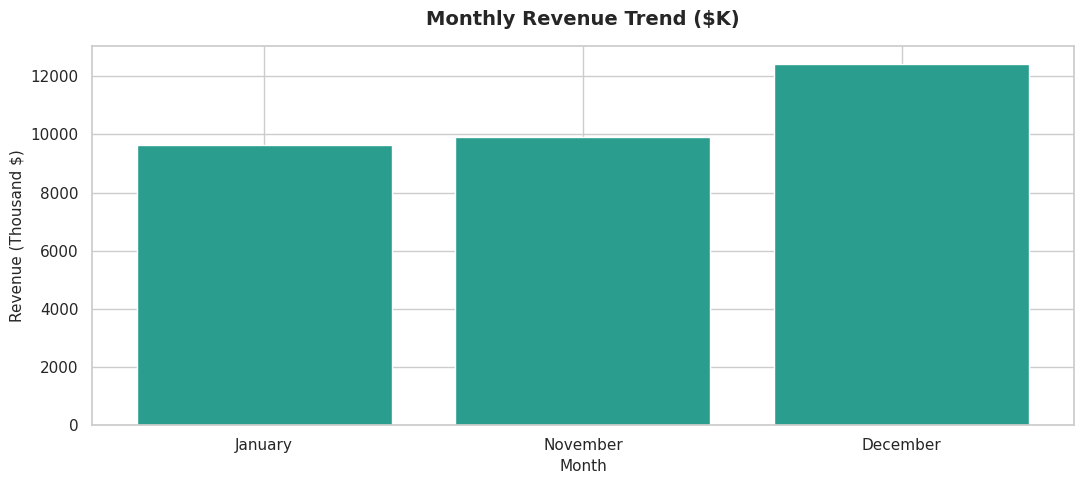

In [46]:
df['month_num'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()

monthly_sales = (df.groupby(['month_num', 'month_name'], as_index=False)['product_price'].sum().sort_values(by='month_num'))

monthly_sales['revenue_k'] = monthly_sales['product_price'] / 1_000

plt.figure(figsize=(11, 5))
plt.bar(
    monthly_sales['month_name'],
    monthly_sales['revenue_k'],
    color="#2A9D8F",
)

plt.title('Monthly Revenue Trend ($K)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Month', fontsize=11)
plt.ylabel('Revenue (Thousand $)', fontsize=11)
plt.tight_layout()
plt.show()

<Figure size 2000x600 with 0 Axes>

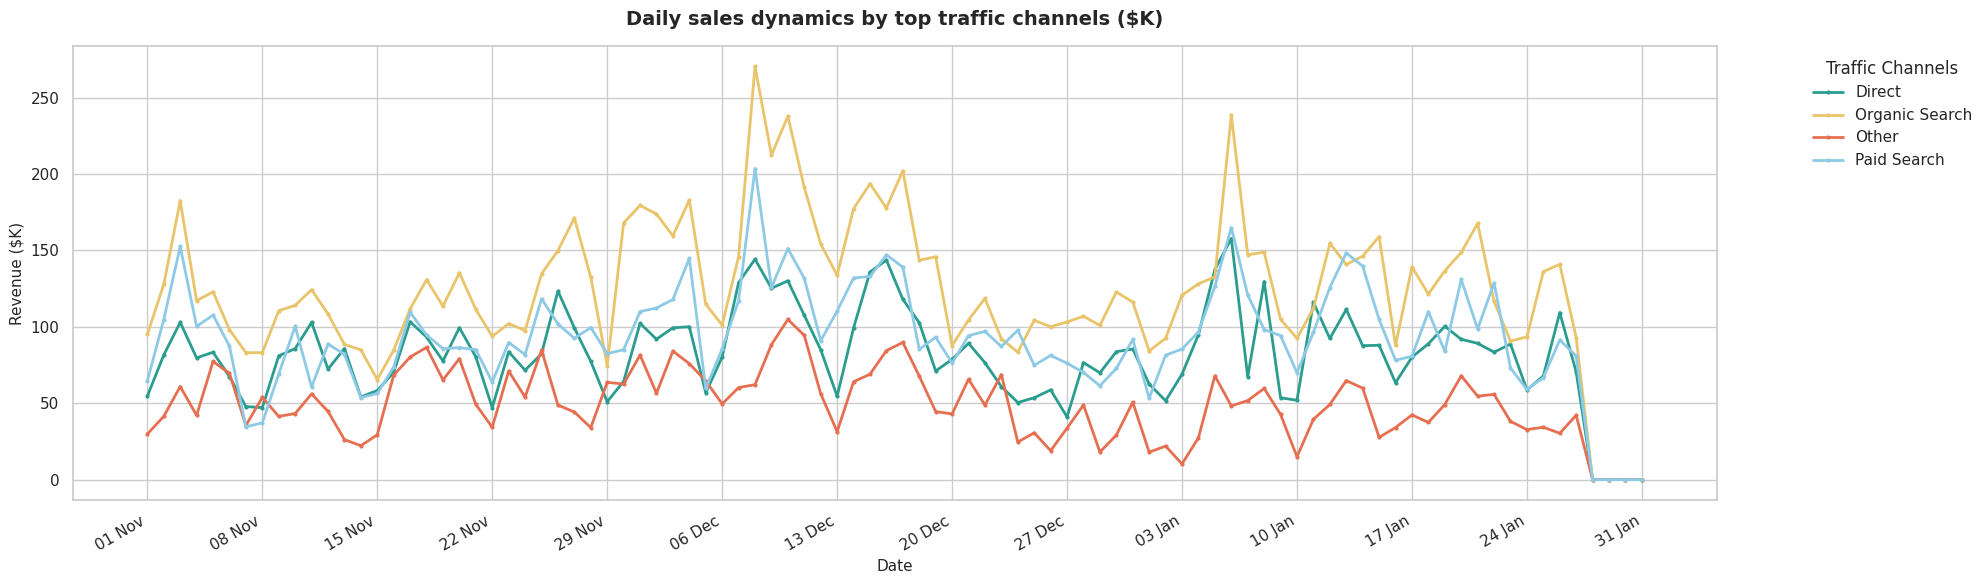

In [47]:
main_channels = ['Organic Search', 'Paid Search', 'Direct']
df['channel_grouped'] = df['traffic_channel'].where(df['traffic_channel'].isin(main_channels), 'Other')

daily_channel = (df.groupby([pd.Grouper(key='date', freq='D'), 'channel_grouped'])['product_price'].sum().unstack(fill_value=0) / 1_000)

daily_channel.index = daily_channel.index.strftime('%d %b')

plt.figure(figsize=(20, 6))

ax = daily_channel.plot(
    kind='line',
    marker='o',
    linewidth=2,
    markersize=2,
    figsize=(20, 6),)

plt.title(
    'Daily sales dynamics by top traffic channels ($K)',
    fontsize=14,
    pad=15,
    fontweight='bold',)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Revenue ($K)', fontsize=11)

tick_positions = range(0, len(daily_channel), 7)
tick_labels = daily_channel.index[tick_positions]
plt.xticks(tick_positions, tick_labels, rotation=30, ha='right')

plt.legend(
    title='Traffic Channels',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,)

plt.tight_layout()
plt.show()

<Figure size 2000x600 with 0 Axes>

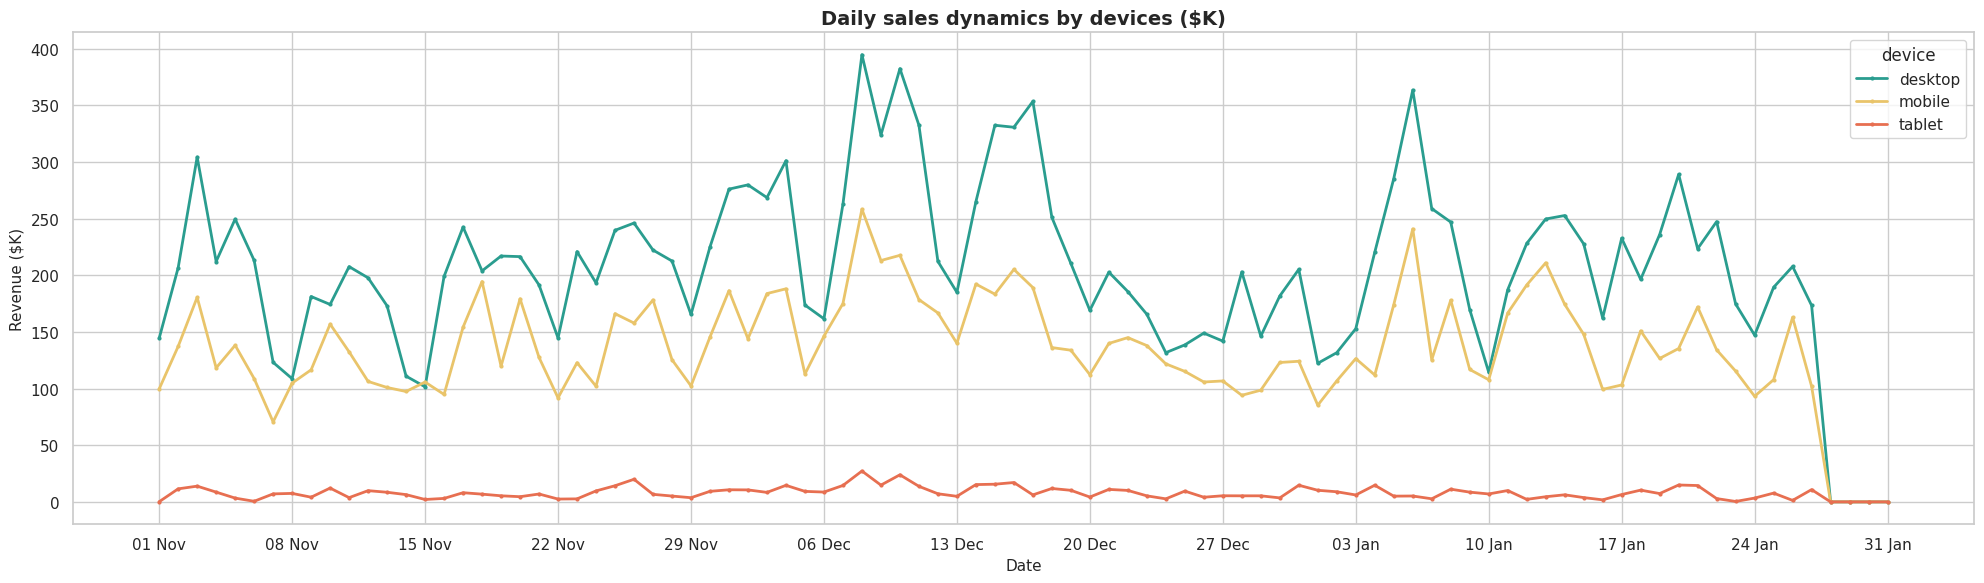

In [48]:
daily_device = (df.groupby([pd.Grouper(key='date', freq='D'), 'device'])['product_price'].sum().unstack(fill_value=0) / 1_000)

daily_device.index = daily_device.index.strftime('%d %b')

plt.figure(figsize=(20, 6))

ax = daily_device.plot(
    kind='line',
    marker='o',
    linewidth=2,
    markersize=2,
    figsize=(20, 6),)

plt.title('Daily sales dynamics by devices ($K)',fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=11)
plt.ylabel('Revenue ($K)', fontsize=11)

tick_positions = range(0, len(daily_device), 7)
tick_labels = daily_device.index[tick_positions]
plt.xticks(tick_positions, tick_labels)

plt.tight_layout()
plt.show()

##Conclusions / Висновки




**Денна динаміка:** денний дохід більшу частину періоду коливається в межах 200–500тис.дол. із чітким тижневим циклом. Найвищі значення: близько 680тис.дол. (8 грудня),  та близько 620тис.дол. (10 грудня) та близько  610тис.дол. (6 січня), перший помітний пік близько 500тис.дол. (3 листопада). Наприкінці періоду (з 28.01 по 31.01.2021) зафіксовано 4 дні без жодного замовлення в усіх каналах і на всіх пристроях. Імовірно, це технічна несправність або інша причина, що не відображає реального попиту, тому ці дні збережено в аналізі як є.

**Місяці:** грудень найсильніший: приблизно 12,4млн.дол. проти приблизно 9,9млн.дол. у листопаді. Січень найнижчий (приблизно 9,6млн.дол.), але це значення занижене днями без замовлень наприкінці місяця, тому говорити про справжнє падіння попиту в січні некоректно.

**Дні тижня:** усі топ-10 категорій мають однакову динаміку: максимум у вівторок–середу, мінімум у суботу–неділю.

**Канали й пристрої:** лінії каналів та пристроїв рухаються синхронно, піки збігаються в усіх сегментах. Desktop стабільно вищий за mobile, а планшети (2,3% доходу) практично не впливають на динаміку.

**Обмеження:** період охоплює лише три місяці, тому річну сезонність оцінити неможливо. Дані за останні 4 дні січня не містять замовлень, що занижує січневі показники.

**Daily Trends:** For the majority of the period, daily revenue fluctuates between 200,000dol. and 500,000dol., exhibiting a clear weekly cycle. The highest figures were recorded on December 8 (near 680,000dol.), December 10 (near 620,000dol.), and January 6 (near 610,000dol.), with an initial notable peak of approximately $500,000 on November 3. Toward the end of the period (January 28–31, 2021), there were four consecutive days with zero orders across all channels and devices. This was likely due to a technical malfunction or another factor unrelated to actual demand; therefore, these days have been retained in the analysis as they appear.

**Monthly Performance:** December was the strongest month, generating approximately 12.4 million dol., compared to roughly $9.9 million dol. in November. January was the weakest month (~9.6 million dol.); however, this figure is skewed downward by the days with zero orders at the end of the month, making it inaccurate to conclude that there was a genuine decline in demand during January.

**Days of the Week:** All top 10 categories follow the same pattern: peaking on Tuesdays and Wednesdays, and reaching a low on Saturdays and Sundays.

**Channels and Devices:** Trends across channels and devices move in sync, with peaks aligning across all segments. Desktop revenue consistently outperforms mobile, while tablets (accounting for 2.3% of revenue) have virtually no impact on the overall trends.

**Limitation:** The period covers only three months, making it impossible to assess annual seasonality. Data for the last 4 days of January contain no orders, which leads to an underestimation of the figures for January.

## Pivot tables / Зведені таблиці


### Sessions by Traffic Channel and Device / Кількість сесій за каналами трафіку та пристроями

In [49]:
pivot_sessions = df.pivot_table(
    index='traffic_channel',
    columns='device',
    values='session_id',
    aggfunc='count',
    fill_value=0,
)
pivot_sessions = pivot_sessions.loc[
    pivot_sessions.sum(axis=1).sort_values(
        ascending=False
    ).index
]
display(pivot_sessions)

device,desktop,mobile,tablet
traffic_channel,,,
Organic Search,72622,49014,2789
Paid Search,55167,37034,2140
Direct,47825,31745,1812
Social Search,16288,10988,638
Undefined,12527,8486,470


### Percent of sessions by Traffic Channel and Device / Відсоток сесій за каналами трафіку та пристроями

In [50]:
pivot_sessions_pct = pivot_sessions.div(pivot_sessions.sum(axis=1), axis=0) * 100
display(pivot_sessions_pct.style.format('{:.1f}%'))

device,desktop,mobile,tablet
traffic_channel,,,
Organic Search,58.4%,39.4%,2.2%
Paid Search,58.5%,39.3%,2.3%
Direct,58.8%,39.0%,2.2%
Social Search,58.4%,39.4%,2.3%
Undefined,58.3%,39.5%,2.2%


### Revenue by Top Product Categories and Top Countries ($K) / Розподіл продажів топ-категорій у розрізі провідних країн (тис.дол.)

In [51]:
top_countries = df.groupby('country')['product_price'].sum().nlargest(5).index
top_categories = df.groupby('product_category')['product_price'].sum().nlargest(10).index
df_filtered = df[
    df['product_category'].isin(top_categories)
    & df['country'].isin(top_countries)
]

pivot_cat_country = (
    df_filtered.pivot_table(
        index='product_category',
        columns='country',
        values='product_price',
        aggfunc='sum',
        fill_value=0,
    )
    / 1_000)
pivot_cat_country = pivot_cat_country.loc[
    pivot_cat_country.sum(axis=1).sort_values(
        ascending=False
    ).index]
pivot_cat_country.index.name = 'Product Category'
display(pivot_cat_country.round(1))

country,Canada,France,India,United Kingdom,United States
Product Category,,,,,
Sofas & armchairs,692.4,187.7,788.4,234.8,3707.1
Chairs,417.7,134.0,544.3,188.5,2619.8
Beds,354.8,116.4,358.3,133.8,2213.1
Bookcases & shelving units,279.0,73.8,364.5,114.0,1567.6
Cabinets & cupboards,181.8,59.1,191.9,71.7,994.5
Outdoor furniture,185.3,40.5,162.3,57.0,929.2
Tables & desks,132.7,42.3,186.2,49.4,777.9
Chests of drawers & drawer units,72.0,21.5,73.1,36.8,382.4
Bar furniture,51.7,11.2,57.7,22.1,330.8


##Conclusions / Висновки

**Канали та пристрої:** розподіл сесій між пристроями практично однаковий у всіх каналах: desktop 58,3–58,8%, mobile 39,0–39,5%, tablet 2,2–2,3%, що збігається зі структурою всього трафіку. Тож канали відрізняються лише обсягом, а не пристроями, з яких приходять користувачі. Найбільший окремий сегмент це Organic Search на desktop (72 622 сесій, 20,8% усього трафіку), далі Paid Search на desktop (15,8%), Organic Search на mobile (14,0%) та Direct на desktop (13,7%).

**Категорії та країни:** структура доходу за категоріями в п'яти провідних країнах дуже схожа. У США, Канаді, Великій Британії та Франції три провідні категорії це Sofas & armchairs, Chairs та Beds, в Індії третє місце займають Bookcases & shelving units. Лише Індія трохи зміщена до дешевших категорій, що узгоджується з її нижчим середнім чеком. Загалом відмінності в доході між країнами пояснюються обсягом, а не асортиментними вподобаннями.

**Channels and Devices:** The distribution of sessions across devices is virtually identical across all channels—desktop (58.3–58.8%), mobile (39.0–39.5%), and tablet (2.2–2.3%)—which aligns with the structure of total traffic. Consequently, channels differ only in terms of volume, not in the devices used by visitors. The largest single segment is Organic Search on desktop (72,622 sessions, accounting for 20.8% of total traffic), followed by Paid Search on desktop (15.8%), Organic Search on mobile (14.0%), and Direct on desktop (13.7%).

**Categories and Countries:** The revenue structure by category is very similar across the top five countries. In the US, Canada, the UK, and France, the top three categories are "Sofas & armchairs," "Chairs," and "Beds," whereas in India, the third spot is held by "Bookcases & shelving units." India shows a slight shift toward lower-priced categories, which correlates with its lower average order value. Overall, differences in revenue between countries are driven by volume rather than variations in product preferences.

##Analysis of correlations

Pearson correlation between sales and quantity of sessions: 0.97
Test statistic and p-value: PearsonRResult(statistic=np.float64(0.9653457824436882), pvalue=np.float64(5.967239468095496e-52))


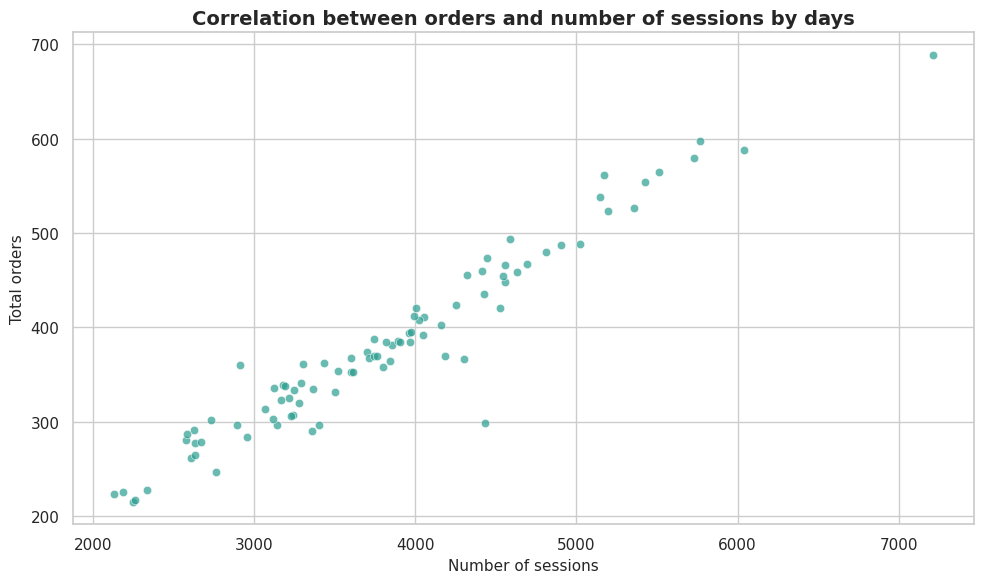

In [52]:
df_filtered = df[~df['date'].between('2021-01-28', '2021-01-31')]

daily_metrics = (
    df_filtered.groupby(pd.Grouper(key='date', freq='D'))
    .agg(
        total_orders=('product_price', 'count'),
        session_count=('session_id', 'count'),
    )
    .reset_index()
)

pearson_correlation = daily_metrics['session_count'].corr(daily_metrics['total_orders'])
print(f'Pearson correlation between sales and quantity of sessions: {pearson_correlation:.2f}')
print(f"Test statistic and p-value: {pearsonr(daily_metrics['session_count'], daily_metrics['total_orders'])}")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=daily_metrics, x='session_count', y='total_orders', alpha=0.7
)

plt.title(
    'Correlation between orders and number of sessions by days',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Number of sessions', fontsize=11)
plt.ylabel('Total orders', fontsize=11)
plt.tight_layout()
plt.show()


Аналіз показав статистично значущий зв'язок між кількістю сесій за день та кількістю замовлень (p-value < 0,001). Коефіцієнт кореляції Пірсона становить 0,97, що свідчить про сильну позитивну лінійну залежність: у дні з більшою кількістю сесій зазвичай більше замовлень. Це узгоджується з точковим графіком, на якому точки утворюють чітку висхідну тенденцію.
Хоча існування кореляції не доводить причинно-наслідкового зв'язку, однак результат дає підстави вважати збільшення трафіку одним із ефективних способів збільшення кількості продажів. Тому доцільно приділити увагу рекламним кампаніям та іншим каналам залучення відвідувачів, одночасно відстежуючи конверсію та якість трафіку.

The analysis revealed a statistically significant relationship between the number of daily sessions and the number of orders (p-value < 0.001). The Pearson correlation coefficient is 0.97, indicating a strong positive linear relationship: days with a higher number of sessions typically see more orders. This is consistent with the scatter plot, where the data points form a clear upward trend.
Although the existence of a correlation does not prove a causal link, the results suggest that increasing traffic is an effective way to boost sales. Therefore, it is advisable to focus on advertising campaigns and other visitor acquisition channels, while simultaneously monitoring conversion rates and traffic quality.

Matrix of correlation daily sales by top-continents:


continents,Americas,Asia,Europe
continents,,,
Americas,1.000000,0.692273,0.669527
Asia,0.692273,1.000000,0.667786
Europe,0.669527,0.667786,1.000000


Test statistic and p-value America vs Asia: PearsonRResult(statistic=np.float64(0.692272592116617), pvalue=np.float64(8.004062946873881e-14))
Test statistic and p-value America vs Europe: PearsonRResult(statistic=np.float64(0.6695272265974656), pvalue=np.float64(9.911408291629347e-13))
Test statistic and p-value Asia vs Europe: PearsonRResult(statistic=np.float64(0.6677857678141952), pvalue=np.float64(1.1908929032637074e-12))


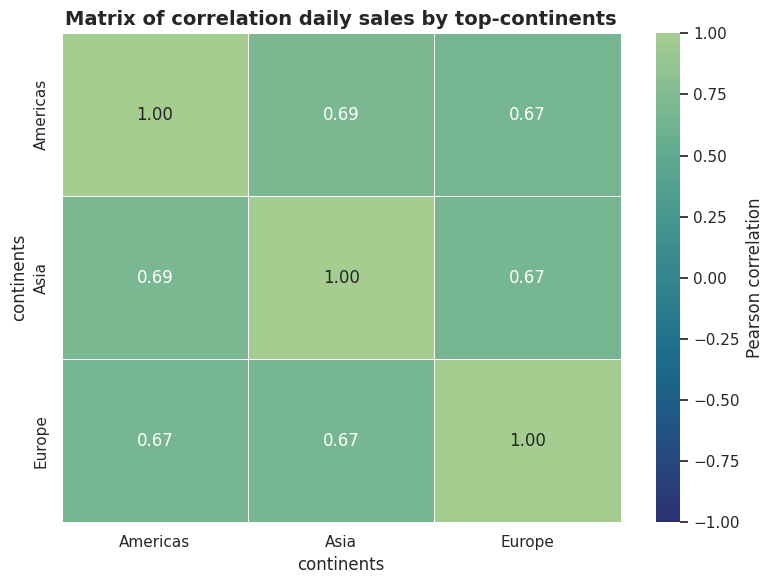

In [53]:
daily_continent = (df_filtered.groupby([pd.Grouper(key='date', freq='D'), 'continent'])['product_price'].sum().unstack(fill_value=0)/ 1_000)
top_continents = ['Americas', 'Asia', 'Europe']
df_top_continents_filtered = daily_continent.loc[~daily_continent.index.to_series().between('2021-01-28', '2021-01-31'),top_continents]
df_top_continents_filtered.columns.name = 'continents'
corr_matrix = df_top_continents_filtered.corr()
print('Matrix of correlation daily sales by top-continents:')
display(corr_matrix)

print(f"Test statistic and p-value America vs Asia: {pearsonr(df_top_continents_filtered['Americas'], df_top_continents_filtered['Asia'])}")
print(f"Test statistic and p-value America vs Europe: {pearsonr(df_top_continents_filtered['Americas'], df_top_continents_filtered['Europe'])}")
print(f"Test statistic and p-value Asia vs Europe: {pearsonr(df_top_continents_filtered['Asia'], df_top_continents_filtered['Europe'])}")

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='crest_r',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Pearson correlation'},
)

plt.title(
    'Matrix of correlation daily sales by top-continents',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

Аналіз взаємозв'язку між продажами на різних континентах показав статистично значущі кореляції (p-value < 0,0001 для всіх пар). Коефіцієнти кореляції Пірсона перевищують 0,67, що свідчить про середній позитивний зв'язок: продажі на різних континентах змінюються синхронно.


An analysis of the interrelationships between sales across different continents revealed statistically significant correlations (p-value < 0.0001 for all pairs). Pearson correlation coefficients exceed 0.67, indicating a middle positive relationship: sales across different continents fluctuate synchronously.

Matrix of correlation daily sales by devices:


devices,desktop,mobile,tablet
devices,,,
desktop,1.000000,0.873201,0.601354
mobile,0.873201,1.000000,0.567394
tablet,0.601354,0.567394,1.000000


Test statistic and p-value Desktop vs Mobile: PearsonRResult(statistic=np.float64(0.8732005616757476), pvalue=np.float64(7.719910860666121e-30))
Test statistic and p-value Desktop vs Tablet: PearsonRResult(statistic=np.float64(0.6013535147282095), pvalue=np.float64(2.3168062296392926e-10))
Test statistic and p-value Mobile vs Tablet: PearsonRResult(statistic=np.float64(0.567393838838939), pvalue=np.float64(3.6938169231464336e-09))


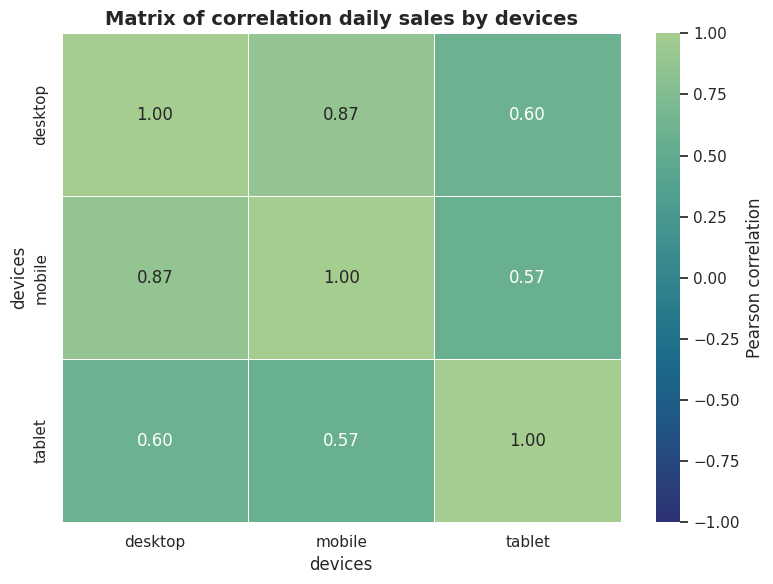

In [54]:
device_types = ['desktop', 'mobile', 'tablet']
df_devices_filtered = daily_device.loc[
    ~daily_device.index.to_series().between('2021-01-28', '2021-01-31'),
    device_types
]
df_devices_filtered.columns.name = 'devices'

corr_matrix = df_devices_filtered.corr()
print('Matrix of correlation daily sales by devices:')
display(corr_matrix)

print(f'Test statistic and p-value Desktop vs Mobile:'f" {pearsonr(df_devices_filtered['desktop'], df_devices_filtered['mobile'])}")
print(f'Test statistic and p-value Desktop vs Tablet:'f" {pearsonr(df_devices_filtered['desktop'], df_devices_filtered['tablet'])}")
print(f'Test statistic and p-value Mobile vs Tablet:'f" {pearsonr(df_devices_filtered['mobile'], df_devices_filtered['tablet'])}")

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='crest_r',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Pearson correlation'},
)

plt.title(
    'Matrix of correlation daily sales by devices',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

Аналіз взаємозв'язку між продажами користувачам, які відвідують сайт із різних пристроїв, показав статистично значущі кореляції ($p < 0,0001$ для всіх пар). Зокрема, коефіцієнт кореляції Пірсона між мобільними пристроями та десктопами становить 0,87, що свідчить про дуже сильний прямий зв'язок. Водночас кореляція для планшетів із рештою пристроїв становить 0,6 і менше, що вказує на помірніший та слабший взаємозв'язок.

An analysis of the relationship between sales for users visiting the site via different devices revealed statistically significant correlations ($p < 0.0001$ for all pairs). Specifically, the Pearson correlation coefficient between mobile devices and desktops is 0.87, indicating a very strong positive relationship. In contrast, the correlation for tablets with other devices is 0.6 or lower, suggesting a more moderate or weaker association.


Matrix of correlation daily sales by top-3 channels:


channels,Organic Search,Paid Search,Direct
channels,,,
Organic Search,1.000000,0.870086,0.837833
Paid Search,0.870086,1.000000,0.814072
Direct,0.837833,0.814072,1.000000


Test statistic and p-value Organic Search vs Paid Search: PearsonRResult(statistic=np.float64(0.8700861209005332), pvalue=np.float64(2.1420029219323245e-29))
Test statistic and p-value Organic Search vs Direct: PearsonRResult(statistic=np.float64(0.8378332649310183), pvalue=np.float64(2.190419660364784e-25))
Test statistic and p-value Paid Search vs Direct: PearsonRResult(statistic=np.float64(0.8140715620898856), pvalue=np.float64(5.896434878977801e-23))


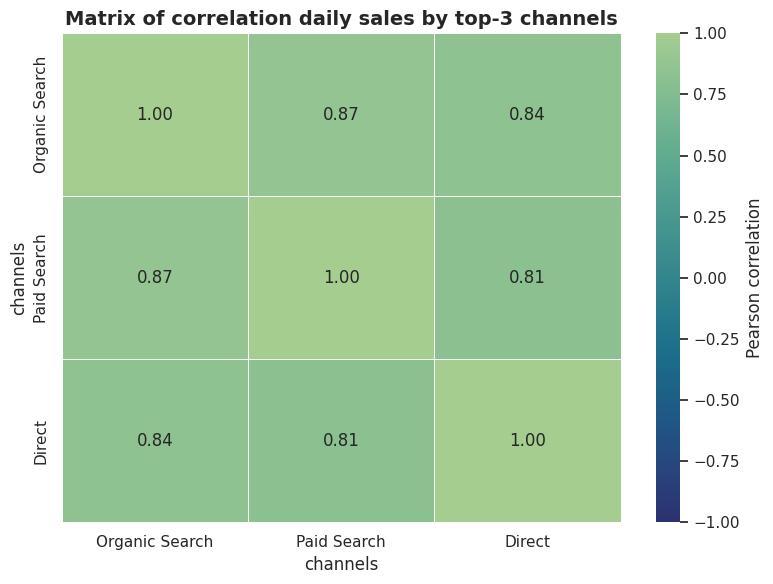

In [55]:
top_channels = ['Organic Search', 'Paid Search', 'Direct']
df_channels_filtered = daily_channel.loc[
    ~daily_channel.index.to_series().between('2021-01-28', '2021-01-31'),
    top_channels
]
df_channels_filtered.columns.name = 'channels'

corr_matrix = df_channels_filtered.corr()
print('Matrix of correlation daily sales by top-3 channels:')
display(corr_matrix)

print(f'Test statistic and p-value Organic Search vs Paid Search:'f" {pearsonr(df_channels_filtered['Organic Search'], df_channels_filtered['Paid Search'])}")
print(f'Test statistic and p-value Organic Search vs Direct:'f" {pearsonr(df_channels_filtered['Organic Search'], df_channels_filtered['Direct'])}")
print(f'Test statistic and p-value Paid Search vs Direct:'f" {pearsonr(df_channels_filtered['Paid Search'], df_channels_filtered['Direct'])}")


plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='crest_r',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Pearson correlation'},
)

plt.title(
    'Matrix of correlation daily sales by top-3 channels',
    fontsize=14,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

Аналіз взаємозв'язку між сумою доходів за різними каналами трафіку показав статистично значущі кореляції (p < 0,0001 для всіх пар). Коефіцієнти кореляції Пірсона перевищують 0,8, що свідчить про дуже сильний позитивний зв'язок.
Така синхронність денних показників вказує на те, що продажі за різними каналами змінюються в одному напрямку. Імовірно, на них впливають спільні фактори, наприклад загальносайтові акції, а не окремі маркетингові кампанії кожного каналу.

An analysis of the relationship between revenue across different traffic channels revealed statistically significant correlations (p < 0,0001 for all pairs). Pearson correlation coefficients exceed 0.8, indicating a very strong positive relationship.
This synchronization of daily metrics suggests that sales across various channels move in the same direction. It is likely that they are influenced by common factors—such as site-wide promotions—rather than by the specific marketing campaigns of individual channels.

##Analysis of difference

###Сomparison of sales to registered and unregistered accounts / Порівняння продажів зареєстрованим та не зареєстрованим акаунтам

Shapiro-Wilk p-value for Guest: 0.0000
Shapiro-Wilk p-value for Registered: 0.0028


user_type,Guest,Registered
date,,
2020-11-01,94.987420,93.277056
2020-11-02,94.077552,150.861745
2020-11-03,99.497903,64.635255
2020-11-04,82.715077,62.261721
2020-11-05,106.440372,83.064262


Wilcoxon W: 1598.0, p-value: 0.13415714701618797


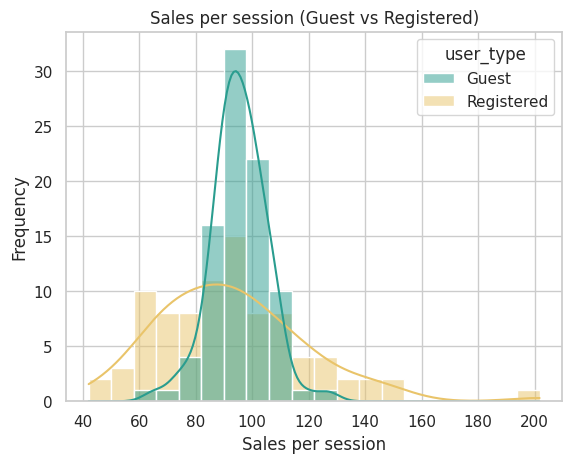

In [56]:
df['user_type'] = np.where(df['account_id'] == 'guest', 'Guest', 'Registered')
daily = (
    df.groupby(['date', 'user_type'])
      .agg(sales=('product_price', 'sum'),
           sessions=('session_id', 'nunique'))
      .reset_index()
)
daily['sales_per_session'] = daily['sales'] / daily['sessions']

_, p_val_guest = shapiro(daily.loc[daily['user_type'] == 'Guest', 'sales_per_session'])
_, p_val_registered = shapiro(daily.loc[daily['user_type'] == 'Registered', 'sales_per_session'])

print(f'Shapiro-Wilk p-value for Guest: {p_val_guest:.4f}')
print(f'Shapiro-Wilk p-value for Registered: {p_val_registered:.4f}')

per_session = daily.pivot(index='date', columns='user_type',
                          values='sales_per_session').dropna()
display(per_session.head())

w_stat, p_value = wilcoxon(per_session['Guest'], per_session['Registered'])
print(f'Wilcoxon W: {w_stat}, p-value: {p_value}')

sns.histplot(per_session, kde=True, bins=20)
plt.title('Sales per session (Guest vs Registered)')
plt.xlabel('Sales per session')
plt.ylabel('Frequency')
plt.show()

Оскільки порівнюються щоденні показники двох груп за одні й ті самі дати, вибірки є парними. Через різний розмір груп порівнювався не сумарний дохід, а середній дохід на сесію. Перевірка нормальності розподілу щоденного доходу по групах (критерій Шапіро-Вілка) показала p-value < 0.05 в обох групах, тому використано непараметричний тест Вілкоксона. Отримане p-value (0.1341) > 0.05, отже статистично значущої різниці в середньому доході на сесію між зареєстрованими та незареєстрованими користувачами не виявлено. Це означає, що попереднє спостереження про більші продажі гостей зумовлене насамперед більшою кількістю їхніх сесій, а не вищою цінністю однієї сесії.

Since the daily metrics of the two groups are compared for the same dates, the samples are paired. Due to the difference in group sizes, the comparison was based on average revenue per session rather than total revenue. A normality test for the daily revenue distribution across the groups (Shapiro-Wilk test) yielded a p-value < 0.05 for both groups; therefore, the non-parametric Wilcoxon test was used. The resulting p-value (0.1341) is greater than 0.05, indicating no statistically significant difference in average revenue per session between registered and unregistered users. This implies that the initial observation of higher sales from guest users is primarily driven by a higher number of sessions, rather than a higher value per individual session.

###Сomparison of sales by traffic channel / Порівняння продажів топ-3 каналам трафіку

Shapiro-Wilk p-value for Direct: 0.0343
Shapiro-Wilk p-value for Organic Search: 0.0123
Shapiro-Wilk p-value for Paid Search: 0.0108
Kruskal-Wallis stat: 96.32097258576631, p-value: 1.2139e-21


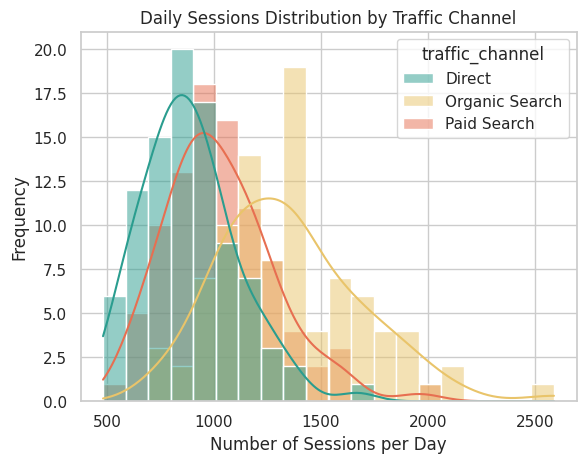

In [57]:
top_3_channels = ['Direct', 'Organic Search', 'Paid Search']
df_top3_channels = df[df['traffic_channel'].isin(top_3_channels)].copy()
df_channels = df_top3_channels.groupby(['date', 'traffic_channel'])['session_id'].count().unstack(fill_value=0)
for channel in df_channels.columns:
  _, p_val = shapiro(df_channels[channel])
  print(f'Shapiro-Wilk p-value for {channel}: {p_val:.4f}')

stat, p_value = kruskal(
    df_channels['Organic Search'],
    df_channels['Paid Search'],
    df_channels['Direct'],
)
print(f'Kruskal-Wallis stat: {stat}, p-value: {p_value:.4e}')

sns.histplot(df_channels, kde=True, bins=20)
plt.title('Daily Sessions Distribution by Traffic Channel')
plt.xlabel('Number of Sessions per Day')
plt.ylabel('Frequency')
plt.show()

За результатами перевірки на нормальність (критерій Шапіро-Вілка), усі три канали трафіку (Organic Search, Paid Search, Direct) мають ненормальний розподіл (p-value < 0.05), через що для порівняння було обрано непараметричний критерій Краскела-Волліса. Отримане значення p-value є дуже малим, що свідчить про наявність статистично значущої різниці в кількості сесій між цими каналами трафіку.

Based on the normality test results (Shapiro-Wilk test), all three traffic channels (Organic Search, Paid Search, Direct) exhibit a non-normal distribution (p-value < 0.05); consequently, the non-parametric Kruskal-Wallis test was selected for comparison. The resulting p-value is very small, indicating a statistically significant difference in the number of sessions across these traffic channels.

###Сomparison of percent of session with Organic Search traffic channels in continents: Americas and Europe / Порівняння відсотка сесій з каналу "Органічний пошук" на континентах: Америка та Європа

In [58]:
target_continents = ['Americas', 'Europe']

df_filtered = df[df['continent'].isin(target_continents)]

continent_channel_stats = df_filtered.groupby('continent').agg(
    total_sessions=('session_id', 'count'),
    organic_sessions=('traffic_channel',
                       lambda x: (x == 'Organic Search').sum())
)

organic_a = continent_channel_stats.loc['Americas', 'organic_sessions']
total_a = continent_channel_stats.loc['Americas', 'total_sessions']

organic_e = continent_channel_stats.loc['Europe', 'organic_sessions']
total_e = continent_channel_stats.loc['Europe', 'total_sessions']

z_stat, p_value = sm.stats.proportions_ztest(
    [organic_a, organic_e],
    [total_a, total_e]
)

print(f"Z-statistic: {z_stat}")
print(f"P-value: {p_value}")


Z-statistic: -0.28951412926103953
P-value: 0.7721879690501752


Отже, після виконання тесту пропорцій для порівняння відсотку сесій з органічним трафіком для Європи та Америки, маємо p-value- 0.7722, що є значно більшим за стандартний рівень значущості (alpha = 0.05). Тому ми не маємо підстав відхиляти нульову гіпотезу про те, що статистично між порівнюваними групами немає статистично значущої різниці. Невеликі відмінності,  йомвірно, є  випадковістю, а не реальним ефектом.

Thus, after performing a test of proportions to compare the percentage of sessions with organic traffic between Europe and the Americas, we obtain a p-value of 0.7722, which is significantly higher than the standard significance level (alpha = 0.05). Therefore, we have no grounds to reject the null hypothesis, which states that there is no statistically significant difference between the groups being compared. The minor differences observed are likely due to chance rather than representing a real effect.

In [59]:
#saving our project to Google Drive for further work on its visualization in Tableau / Зберігаємо наш проєкт на гугл-диск для подальшої роботи над його візуалізацією у Tableau
df.to_csv('/content/drive/My Drive/portfolio.csv', encoding='utf-8-sig')

##Main conclusions / Загальні висновки

Аналіз e-commerce продажів інтернет магазину з інтерактивною візуалізацією: https://public.tableau.com/views/portfolio_17931156253050/Dashboard1?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

За три місяці аналізованого періоду (01.11.2020 - 31.01.2021) магазин отримав 349 545 сесій, 33 538 замовлень і 31,97 млн $ доходу. Конверсія становить 9,59%, середній чек 953дол., медіанний 445дол., дохід на сесію 91,47дол.

**Ключові інсайти:**

*   Дохід визначає асортимент, а не сегмент. Sofas & armchairs, Chairs і Beds дають 60,9% доходу. Bookcases лідирують за кількістю замовлень (22,8%), але приносять лише 11,4% доходу, а Sofas мають 12,8% замовлень і 26,2% доходу.
*   CR і AOV майже однакові в усіх зрізах (CR 9,0–9,9%, AOV 930–1 000дол. за пристроями, каналами, мовами, континентами). Слабкого сегмента, який треба «виправляти», немає, тому ріст слід шукати в обсязі трафіку та структурі товарів.
*   Дохід географічно сконцентрований. США дають 43,6%, разом з Індією та Канадою 60%. Азія (23,8%) і Європа (18,6%) мають потенціал при тій самій конверсії.
*   Виражена сезонність. Пік доходу припадає на вівторок–середу, мінімум на вихідні.
*   Якість даних. 33% сесій без мови, 6% з каналом «Undefined», 4 останні дні січня без замовлень (імовірно, збій обліку).
*   Останні 4 дні без продажів були виключені з статистичного аналізу взаємозв'язків оскільки вони викривляють ці розрахунки.

**Практичні рекомендації:**

*   Спрямовувати рекламний бюджет на високочекові категорії (Sofas & armchairs, Chairs, Beds). А дешевші товари пропонувати як додаток, щоб збільшити чек.
*   Пріоритетно розширювати присутність в Азії та Європі. Тому варто приділити більшу увагу маркетинговим акціям спрямованим саме на ці континенти.
*   Планувати кампанії за днями тижня. Акції й розсилки краще ставити на початок тижня, а для вихідних придумати окремі пропозиції, які б підвищили загальні продажі.
*   Для подальшого коректного аналізу варто провести роботу з мітками сесій для уникнення або зменшення пропусків в даних по: країнам, каналах трафіку, браузерам, мовам, тощо.



Analysis of an online store's e-commerce sales, featuring interactive visualization: https://public.tableau.com/views/portfolio_17931156253050/Dashboard1?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

Over the three-month period analyzed (November 1, 2020 – January 31, 2021), the store generated 349,545 sessions, 33,538 orders, and 31.97 million dol. in revenue. The conversion rate (CR) stands at 9.59%, with an average order value (AOV) of 953dol., a median order value of 445dol., and revenue per session of 91.47dol.

**Key Insights:**

*   Revenue is driven by product category rather than customer segment. "Sofas & armchairs," "Chairs," and "Beds" account for 60.9% of total revenue. While "Bookcases" lead in terms of order volume (22.8%), they contribute only 11.4% to revenue; conversely, "Sofas" account for 12.8% of orders but generate 26.2% of revenue.
*   The conversion rate (CR) and average order value (AOV) remain remarkably consistent across various segments—ranging from 9.0% to 9.9% for CR and $930 to $1,000 for AOV—regardless of device, channel, language, or continent. There is no specific underperforming segment requiring a "fix"; therefore, growth should be pursued by increasing traffic volume and optimizing the product mix.
*   Revenue is geographically concentrated. The United States accounts for 43.6% of revenue, and together with India and Canada, these regions represent 60% of the total. Asia (23.8%) and Europe (18.6%) show potential, maintaining similar conversion rates.
*   Pronounced seasonality: Revenue peaks on Tuesdays and Wednesdays, while hitting a low on weekends.
*   Data quality issues: 33% of sessions lack language data, 6% are attributed to an "Undefined" channel, and no orders were recorded during the last four days of January (likely a tracking error).
*   The last 4 days with no sales were excluded from the statistical analysis of correlations, as they distort these calculations.

**Practical Recommendations:**

*   Allocate the advertising budget toward high-ticket categories (Sofas & armchairs, Chairs, Beds). Offer lower-priced items as add-ons to increase the average order value.
*   Prioritize expanding presence in Asia and Europe. So greater focus should be placed on marketing campaigns specifically targeting these continents.
*   Plan campaigns based on the day of the week. Schedule promotions and email campaigns for the beginning of the week, while developing specific offers for the weekend to boost overall sales.
*   To ensure accurate future analysis, improve session tagging to eliminate or minimize data gaps regarding countries, traffic channels, browsers, languages, etc.